# Project - Bank Marketing: who should the bank call first?
**FRA503 Introduction to Machine Learning (1/2569)** · Steps 2-13 of the score sheet (target exploration → feature extraction)

**Problem B (short):** the bank has limited call capacity, but only ~11% of called customers open a term deposit. Using only information known **before** the call, rank customers by their probability of subscribing so the most likely ones are called first.
* **Data:** UCI Bank Marketing, `bank-additional-full.csv` (Portuguese bank phone campaigns, May 2008 - Nov 2010, 41,188 rows, 20 inputs)
* **Sample:** one phone contact with one customer · **Target:** `y` (subscribed: yes / no)

**Techniques used (all from Ch02 + the course demo):** `describe` / `nunique` / `VarianceThreshold`, histograms, bar charts and box plots, z-score (2-3 SD) rule and capping, the >30 % missing rule, box plot by class + ANOVA `f_oneway`, crosstab bar charts + `chi2_contingency`, `mutual_info_classif`, correlation matrix, `StandardScaler` + `PCA`.

## Setup and data loading

In [24]:
%matplotlib inline
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import f_oneway, chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

SEED = 42
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4g}')
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#8a8a85'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e4e3de',
                     'axes.titlesize': 10, 'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8})
MONTHS = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
DAYS = ['mon', 'tue', 'wed', 'thu', 'fri']

12 exact duplicate rows are removed first, so a row and its copy cannot end up on both sides of the split.

In [25]:
DATA_PATH = Path('~/paddy/dataset/bank-additional-full.csv').expanduser()
raw = pd.read_csv(DATA_PATH, sep=';')                     # the file is ';'-separated
print('shape:', raw.shape, '| exact duplicate rows:', raw.duplicated().sum())

df = raw.drop_duplicates().copy()                          # duplicates could sit in both train and test
df['y01'] = (df['y'] == 'yes').astype(int)                 # 1 = subscribed
CAT = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
NUM = ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
MACRO = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
print('after dropping duplicates:', df.shape)
df.head()

shape: (41188, 21) | exact duplicate rows: 12
after dropping duplicates: (41176, 22)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,y01
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.99,-36.4,4.857,"5,191",no,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.99,-36.4,4.857,"5,191",no,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.99,-36.4,4.857,"5,191",no,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.99,-36.4,4.857,"5,191",no,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.99,-36.4,4.857,"5,191",no,0


## Train / test split (before any exploration)
Every decision below (outlier cap, merges, test results, PCA) is learned from data. To keep the test set unseen, the split is done **first** and steps 2-13 use `train` only.
* 80 / 20 random split, stratified on `y`, `random_state=42`
* A time-ordered split (train on old calls, test on new ones) belongs to the extra experiment D and is done at the modelling stage.

In [26]:
train, test = train_test_split(df, test_size=0.20, random_state=SEED, stratify=df['y'])
train, test = train.sort_index(), test.sort_index()         # keep the file's time order inside each part
print('train', train.shape, '| test', test.shape)
print(f"subscribe rate: all {df.y01.mean():.2%} | train {train.y01.mean():.2%} | test {test.y01.mean():.2%}")
tr = train.copy()                                           # every step below looks at train only

train (32940, 22) | test (8236, 22)
subscribe rate: all 11.27% | train 11.27% | test 11.27%


# 2 · Basic data exploration - target
Guideline checks: balance, skewness, outliers.

,count,share %
y,,
no,29229,88.73
yes,3711,11.27


imbalance  no : yes = 7.9 : 1
accuracy of a model that always says "no" = 88.7%


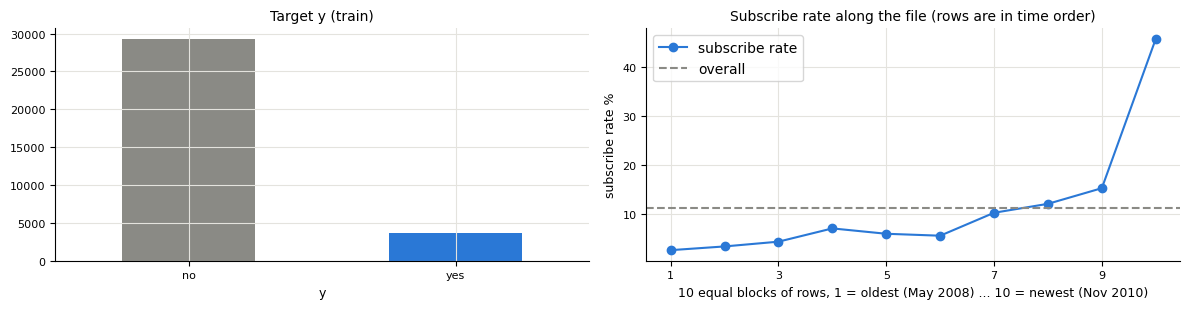

subscribe rate per block (%): [2.7, 3.4, 4.4, 7.1, 6.0, 5.6, 10.3, 12.1, 15.3, 45.7]


In [27]:
cnt = tr['y'].value_counts()
display(pd.DataFrame({'count': cnt, 'share %': cnt / len(tr) * 100}))
print(f'imbalance  no : yes = {cnt["no"] / cnt["yes"]:.1f} : 1')
print(f'accuracy of a model that always says "no" = {cnt["no"] / len(tr):.1%}')

rate_t = tr.groupby(pd.qcut(tr.index, 10, labels=range(1, 11)))['y01'].mean() * 100
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
cnt.plot.bar(ax=ax[0], color=[GREY, BLUE], rot=0, title='Target y (train)')
rate_t.plot(ax=ax[1], marker='o', color=BLUE, label='subscribe rate', title='Subscribe rate along the file (rows are in time order)')
ax[1].axhline(tr.y01.mean() * 100, color=GREY, ls='--', label='overall')
ax[1].set(xlabel='10 equal blocks of rows, 1 = oldest (May 2008) ... 10 = newest (Nov 2010)', ylabel='subscribe rate %'); ax[1].legend()
plt.tight_layout(); plt.show()
print('subscribe rate per block (%):', rate_t.round(1).tolist())

**Reading**
* **Imbalanced:** 3,711 yes vs 29,229 no (11.3 %), about **7.9 : 1**. A model that always says "no" already gets 88.7 % accuracy, so accuracy is useless here. Ranking metrics (PR-AUC, share of subscribers found in the top-ranked calls) are used later.
* **Skewness / outliers:** `y` is a binary label, so neither applies.
* **Changes over time:** the subscribe rate rises from **2.7 %** in the oldest tenth of the rows to **45.7 %** in the newest. The rate depends on the period, which is the reason for experiment D (does the model still work when the market changes?).
* **Decision:** no resampling now; class imbalance is handled in modelling (e.g. `class_weight`, decision threshold).

# 3 · Basic data exploration - features
Goal: volume, column types, distributions, and reject columns that clearly cannot be used.
Tools: summary table, `describe()`, `nunique()` (< 20 unique values → likely categorical), `VarianceThreshold`, histograms, bar charts.

In [28]:
COLS = CAT + NUM
info = pd.DataFrame({'dtype': tr[COLS].dtypes.astype(str), 'n_unique': tr[COLS].nunique(),
                     'top value': [tr[c].value_counts().index[0] for c in COLS],
                     'top share %': [tr[c].value_counts(normalize=True).iloc[0] * 100 for c in COLS]})
info['kind'] = np.where(info.index.isin(CAT), 'categorical', np.where(info.n_unique < 20, 'numeric, few values', 'numeric, continuous'))
display(info)
display(tr[NUM].describe().T)

vt = VarianceThreshold(threshold=0).fit(tr[NUM])
print('zero-variance numeric columns:', [c for c, keep in zip(NUM, vt.get_support()) if not keep])
print('columns where one value covers > 80% of rows:', info.index[info['top share %'] > 80].tolist())

,dtype,n_unique,top value,top share %,kind
job,object,12,admin.,25.1,categorical
marital,object,4,married,60.46,categorical
education,object,8,university.degree,29.51,categorical
default,object,3,no,79.18,categorical
housing,object,3,yes,52.45,categorical
loan,object,3,no,82.44,categorical
contact,object,2,cellular,63.57,categorical
month,object,10,may,33.45,categorical
day_of_week,object,5,thu,20.76,categorical
poutcome,object,3,nonexistent,86.31,categorical


,count,mean,std,min,25%,50%,75%,max
age,3.294e+04,40.02,10.45,17,32,38,47,98
duration,3.294e+04,257.7,257.5,0,102,179,319,"4,199"
campaign,3.294e+04,2.562,2.77,1,1,2,3,56
pdays,3.294e+04,962.6,186.6,0,999,999,999,999
previous,3.294e+04,0.1738,0.4986,0,0,0,0,7
emp.var.rate,3.294e+04,0.08013,1.572,-3.4,-1.8,1.1,1.4,1.4
cons.price.idx,3.294e+04,93.58,0.5795,92.2,93.08,93.75,93.99,94.77
cons.conf.idx,3.294e+04,-40.51,4.629,-50.8,-42.7,-41.8,-36.4,-26.9
euribor3m,3.294e+04,3.618,1.736,0.634,1.344,4.857,4.961,5.045
nr.employed,3.294e+04,"5,167",72.4,"4,964","5,099","5,191","5,228","5,228"


zero-variance numeric columns: []
columns where one value covers > 80% of rows: ['loan', 'poutcome', 'pdays', 'previous']


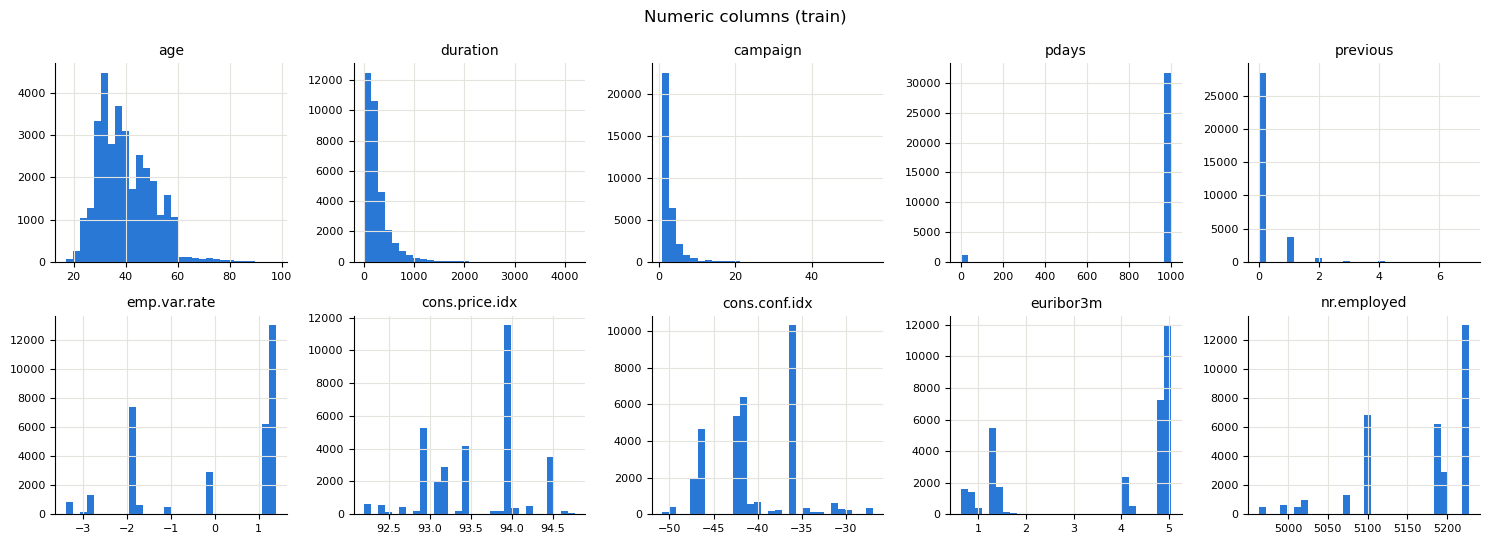

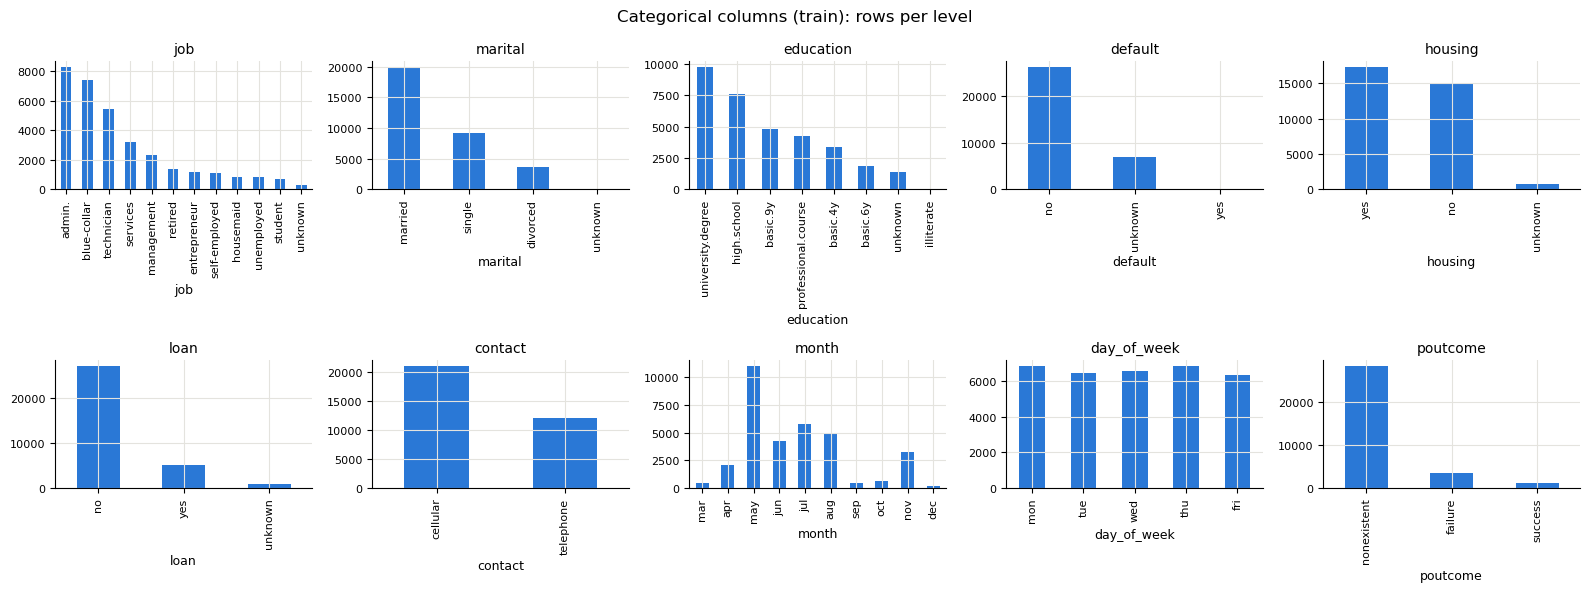

In [29]:
tr[NUM].hist(bins=30, figsize=(15, 5.5), layout=(2, 5), color=BLUE)
plt.suptitle('Numeric columns (train)'); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 5, figsize=(16, 6))
for a, c in zip(ax.ravel(), CAT):
    vc = tr[c].value_counts()
    if c == 'month': vc = vc.reindex(MONTHS)
    if c == 'day_of_week': vc = vc.reindex(DAYS)
    vc.plot.bar(ax=a, color=BLUE, title=c)
plt.suptitle('Categorical columns (train): rows per level'); plt.tight_layout(); plt.show()

**Reading**
* 32,940 training rows, 20 inputs: 10 categorical (text) + 10 numeric. No column is constant (`VarianceThreshold` drops nothing).
* `loan`, `poutcome`, `pdays`, `previous` have one value covering > 80 % of rows. They are **not** dropped by the 80 % rule: here the rare values (e.g. `poutcome = success`) may be the informative ones, which steps 7 and 10 test against `y`.
* **Skewed:** `campaign` (median 2, max 56), `previous` (86 % zeros), `duration`. `pdays` is 96 % "999", a code rather than a number (step 5).
* The 5 macro columns (`emp.var.rate` … `nr.employed`) take only 10-26 values (`euribor3m` 312): they are monthly/quarterly economic indicators, identical for everyone called in the same period.
* `default = yes` appears in only 2 rows; 6 text columns contain `unknown` (step 5).

**Reject `duration`.** The call length is known only **after** the call ends, so it cannot be used to decide whom to call (the UCI description also says to use it only as a benchmark). The check below shows why it would leak the answer:

In [30]:
# duration: is it known before the call?
display(tr.groupby('y')['duration'].describe()[['count', 'mean', '50%', 'max']])
print('calls with duration = 0 seconds ->', tr.loc[tr.duration == 0, 'y'].value_counts().to_dict())

FEATURES = [c for c in COLS if c != 'duration']
print(f'{len(FEATURES)} columns go on to the next steps (duration rejected)')

,count,mean,50%,max
y,,,,
no,2.923e+04,220.5,164,"3,785"
yes,"3,711",550.7,449,"4,199"


calls with duration = 0 seconds -> {'no': 4}
19 columns go on to the next steps (duration rejected)


Calls that ended in "yes" last 2.7× longer (median 449 s vs 164 s), and every 0-second call is "no": `duration` describes the outcome of the call, not the customer. **Rejected**, 19 columns go on.

# 4 · Outlier analysis
Tools: box plots and the z-score rule (|z| > 3, the slide's "2-3 SD from the mean"). Each flagged column is then checked: data error or real customer? Do the flagged rows behave differently on `y`?

,mean,mean + 3 SD,max,n |z|>3,% |z|>3,subscribe % if |z|>3,subscribe % otherwise
age,40.02,71.38,98,303,0.9199,47.19,10.93
campaign,2.562,10.87,56,676,2.052,2.959,11.44
previous,0.1738,1.67,7,849,2.577,49.59,10.25
emp.var.rate,0.08013,4.795,1.4,0,0,NaN,11.27
cons.price.idx,93.58,95.31,94.77,0,0,NaN,11.27
cons.conf.idx,-40.51,-26.62,-26.9,0,0,NaN,11.27
euribor3m,3.618,8.826,5.045,0,0,NaN,11.27
nr.employed,"5,167","5,384","5,228",0,0,NaN,11.27


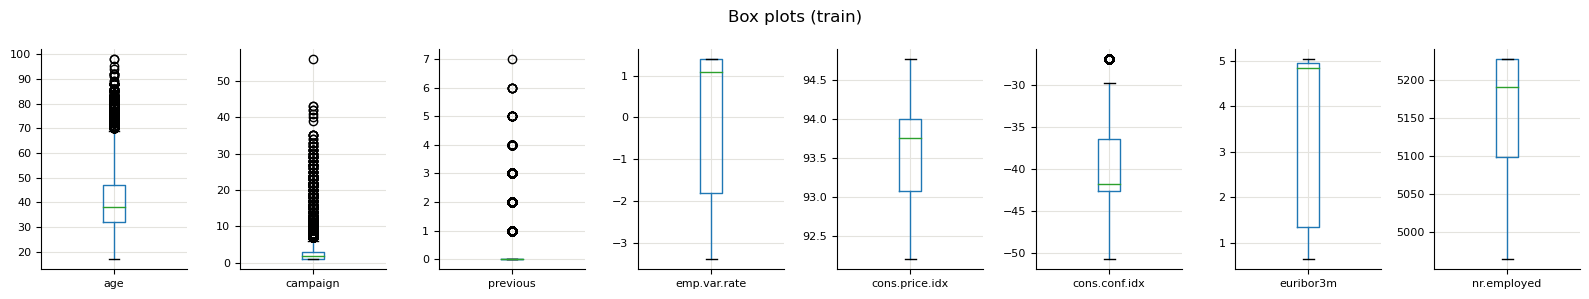

In [31]:
CONT = ['age', 'campaign', 'previous'] + MACRO          # pdays is a coded column, handled in step 5
z = (tr[CONT] - tr[CONT].mean()) / tr[CONT].std()
flag = z.abs() > 3
out = pd.DataFrame({'mean': tr[CONT].mean(), 'mean + 3 SD': tr[CONT].mean() + 3 * tr[CONT].std(), 'max': tr[CONT].max(),
                    'n |z|>3': flag.sum(), '% |z|>3': flag.mean() * 100,
                    'subscribe % if |z|>3': [tr.loc[flag[c], 'y01'].mean() * 100 for c in CONT],
                    'subscribe % otherwise': [tr.loc[~flag[c], 'y01'].mean() * 100 for c in CONT]})
display(out)

fig, ax = plt.subplots(1, len(CONT), figsize=(16, 3))
for a, c in zip(ax, CONT): tr.boxplot(column=c, ax=a)
plt.suptitle('Box plots (train)'); plt.tight_layout(); plt.show()

| Column | Flagged (\|z\| > 3) | Reading | Decision |
|---|---|---|---|
| `age` | 303 rows (0.9 %), age > 71 | real retirees (max 98 is plausible); they subscribe **47 %** vs 11 % | **keep**: informative, not an error |
| `previous` | 849 rows (2.6 %), ≥ 2 earlier contacts | real counts 0-7; they subscribe **50 %** | **keep** |
| `campaign` | 676 rows (2.1 %), > 10.9 calls, max 56 | real, but a long thin tail; only **3 %** subscribe; extreme values would pull a linear model | **cap** |
| 5 macro columns | none | - | - |

**Treatment for `campaign`:** values above the 99th percentile of train are replaced by that value (the demo's "replace with the nearest logical value"). The cap is learned on train and reused on test.

campaign values above the 3-SD limit: {11: 142, 12: 101, 13: 70, 14: 48, 15: 39, 16: 41, 17: 44, 18: 23, 19: 19, 20: 20, 21: 20, 22: 12, 23: 11, 24: 11, 25: 8, 26: 6, 27: 10, 28: 7, 29: 9, 30: 6, 31: 6, 32: 4, 33: 4, 34: 2, 35: 5, 39: 1, 40: 1, 41: 1, 42: 2, 43: 2, 56: 1}
cap = 14 (99th percentile of train)


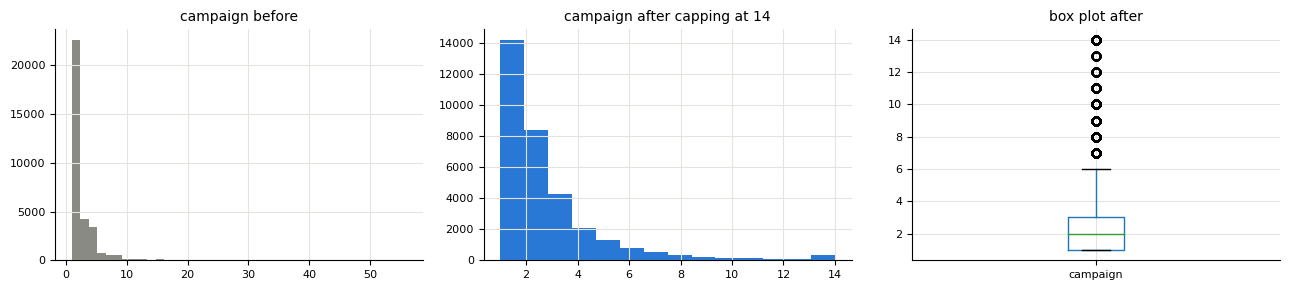

In [32]:
print('campaign values above the 3-SD limit:', tr.loc[flag['campaign'], 'campaign'].value_counts().sort_index().to_dict())
CAMPAIGN_CAP = int(tr['campaign'].quantile(0.99))           # learned on train, reused on test later
print('cap =', CAMPAIGN_CAP, '(99th percentile of train)')
tr['campaign'] = tr['campaign'].clip(upper=CAMPAIGN_CAP)

fig, ax = plt.subplots(1, 3, figsize=(13, 3))
train['campaign'].hist(ax=ax[0], bins=40, color=GREY); ax[0].set_title('campaign before')
tr['campaign'].hist(ax=ax[1], bins=CAMPAIGN_CAP, color=BLUE); ax[1].set_title(f'campaign after capping at {CAMPAIGN_CAP}')
tr.boxplot(column='campaign', ax=ax[2]); ax[2].set_title('box plot after')
plt.tight_layout(); plt.show()

After capping at **14** calls, the tail is gone and the shape of the bulk is unchanged.

# 5 · Missing-value analysis
Two kinds: **explicit** (`NaN`) and **disguised** (`unknown` text, `pdays = 999`).
Guideline rules: > 30 % missing → reject the column; only a few rows → delete them; otherwise impute (mean / median / mode) or keep "missing" as its own category.

In [33]:
print('explicit missing cells (NaN):', int(tr.isnull().sum().sum()))

hidden = {c: tr[c] == 'unknown' for c in CAT if (tr[c] == 'unknown').any()}
hidden['pdays'] = tr['pdays'] == 999                        # 999 = "never contacted before" (code, not a number of days)
miss = pd.DataFrame({'n missing': {c: m.sum() for c, m in hidden.items()},
                     '% missing': {c: m.mean() * 100 for c, m in hidden.items()},
                     'subscribe % when missing': {c: tr.loc[m, 'y01'].mean() * 100 for c, m in hidden.items()},
                     'subscribe % when present': {c: tr.loc[~m, 'y01'].mean() * 100 for c, m in hidden.items()}})
display(miss.sort_values('% missing', ascending=False))

explicit missing cells (NaN): 0


,n missing,% missing,subscribe % when missing,subscribe % when present
pdays,31733,96.34,9.236,64.62
default,6857,20.82,5.308,12.83
education,1389,4.217,14.9,11.11
housing,779,2.365,11.68,11.26
loan,779,2.365,11.68,11.26
job,267,0.8106,12.36,11.26
marital,68,0.2064,16.18,11.26


| Column | Missing | Reading | Decision |
|---|---|---|---|
| `pdays` | 96.3 % = 999 | > 30 % → cannot be used as a number. But "999 or not" is strongly related to `y` (64.6 % vs 9.2 %) | **reject `pdays`**, keep the information as a 0/1 flag `pdays_contacted` |
| `default` | 20.8 % `unknown` | < 30 %. Not random: `unknown` subscribe 5.3 % vs 12.8 %. Mode imputation (→ `no`) would erase this | **keep `unknown` as a level** |
| `education`, `housing`, `loan`, `job`, `marital` | 0.2-4.2 % | deleting rows would lose ~2,900 rows; mode imputation would invent values | **keep `unknown` as a level** (one-hot will turn it into its own column) |

In [34]:
tr['pdays_contacted'] = (tr['pdays'] != 999).astype(int)    # keeps the only usable part of pdays
FEATURES = [c for c in FEATURES if c != 'pdays'] + ['pdays_contacted']
print('pdays dropped, pdays_contacted added ->', len(FEATURES), 'columns')

pdays dropped, pdays_contacted added -> 19 columns


# 6 · Feature selection - continuous features: visual
Box plot of each feature for `y = no` vs `y = yes` (as in the demo's box plot by category). Boxes at different heights → the feature is related to `y`.

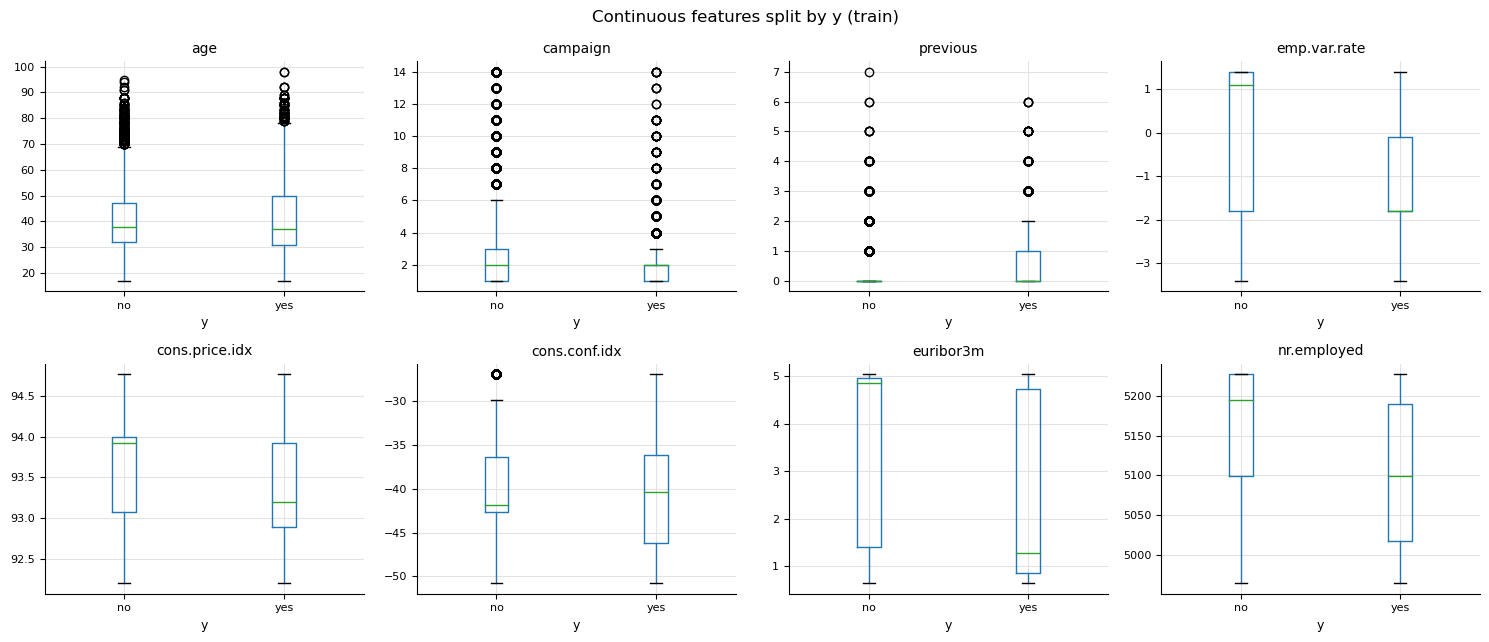

y,no,yes,difference
age,39.89,41.03,1.141
campaign,2.55,2.047,-0.5031
previous,0.1331,0.4942,0.3611
emp.var.rate,0.2446,-1.215,-1.459
cons.price.idx,93.6,93.36,-0.2417
cons.conf.idx,-40.6,-39.81,0.7892
euribor3m,3.806,2.14,-1.665
nr.employed,"5,176","5,096",-80.18


In [35]:
fig, ax = plt.subplots(2, 4, figsize=(15, 6.5))
for a, c in zip(ax.ravel(), CONT):
    tr.boxplot(column=c, by='y', ax=a); a.set_title(c); a.set_xlabel('y')
plt.suptitle('Continuous features split by y (train)'); plt.tight_layout(); plt.show()
display(tr.groupby('y')[CONT].mean().T.assign(difference=lambda t: t['yes'] - t['no']))

**Reading**
* **Macro columns:** clear shift. "Yes" calls happened when interest rates and employment were low (mean `euribor3m` 2.14 vs 3.81, `nr.employed` 5,096 vs 5,176).
* `previous`: subscribers had more earlier contacts (mean 0.49 vs 0.13). `campaign`: subscribers needed fewer calls (2.0 vs 2.6).
* `age`: medians almost equal, but the "yes" box is wider at **both** ends: young and old customers subscribe more (U-shape). A comparison of means hides this.

# 7 · Feature selection - continuous features: statistics
| Tool | Measures | Note |
|---|---|---|
| ANOVA `f_oneway` (H0: same mean in both classes) | difference in means (linear) | assumes ~normal data, similar variance, independent rows; with 3.7k / 29k rows per class it is robust to non-normality |
| correlation with `y` (0/1) | direction and linear strength | linear only |
| `mutual_info_classif` | any kind of dependency | ranking only, no p-value; columns with < 20 values marked discrete |

**Rule:** candidate if p < 0.05. With 33k rows even tiny differences give p < 0.05, so MI and |corr| are used to judge how strong the relation is.

In [36]:
rows = {}
for c in CONT:
    F, p = f_oneway(*tr.groupby('y')[c].apply(list))       # ANOVA: H0 = mean is the same for yes and no
    rows[c] = {'F': F, 'p-value': p, 'corr with y': tr[c].corr(tr['y01'])}
num_tab = pd.DataFrame(rows).T
num_tab['MI'] = mutual_info_classif(tr[CONT], tr['y01'], discrete_features=(tr[CONT].nunique() < 20).values, random_state=SEED)
num_tab['p < 0.05'] = num_tab['p-value'] < 0.05
display(num_tab.sort_values('MI', ascending=False))

,F,p-value,corr with y,MI,p < 0.05
euribor3m,"3,338",0,-0.3033,0.07323,True
cons.price.idx,583,1.097e-127,-0.1319,0.06957,True
cons.conf.idx,95.98,1.246e-22,0.0539,0.06848,True
nr.employed,"4,604",0,-0.3502,0.0612,True
emp.var.rate,"3,108",0,-0.2936,0.05357,True
previous,"1,823",0,0.229,0.01914,True
age,39.3,3.673e-10,0.03452,0.01307,True
campaign,160.2,1.229e-36,-0.06958,0.003169,True


**Reading**
* All 8 have p < 0.05.
* **Strongest:** the 5 macro columns (MI 0.054-0.073, |r| up to 0.35).
* `previous`: r = 0.23, MI = 0.019.
* `age`: r is only 0.035, but MI = 0.013 ranks it above `campaign`: the relation is **non-linear** (the U-shape). This is the slide's "F-test sees only linear dependency, MI sees any" case.
* `campaign`: weakest (MI 0.003, r = -0.07), but the direction makes sense (more calls → less likely).

# 8 · Feature selection summary - continuous features
| Feature | Visual | Statistics | Decision |
|---|---|---|---|
| `euribor3m`, `nr.employed`, `emp.var.rate`, `cons.price.idx`, `cons.conf.idx` | clear shift | p ≈ 0, MI 0.054-0.073 | **keep** → redundancy check (step 12) |
| `previous` | more contacts → yes | F = 1,823, MI 0.019 | **keep** |
| `age` | U-shape | p = 3.7e-10, r = 0.035, MI 0.013 | **keep**, non-linear → step 13 |
| `campaign` | fewer calls → yes | p = 1.2e-36, MI 0.003 | **keep** (weak) |

**Caution:** the 4 monthly indicators form only 26 distinct combinations (about one per month of calls; `euribor3m` changes daily), so the macro columns describe **when** the call happened, not **who** the customer is. They help choose good periods but carry a drift risk (experiment D).

In [37]:
CONT_KEEP = ['age', 'campaign', 'previous'] + MACRO
print('continuous features kept:', CONT_KEEP)

continuous features kept: ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


# 9 · Feature selection - categorical features: visual
Subscribe rate in each level (`pd.crosstab(..., normalize='index')`). Dashed line = overall rate (11.3 %). Bars far from the line → the feature is related to `y`.

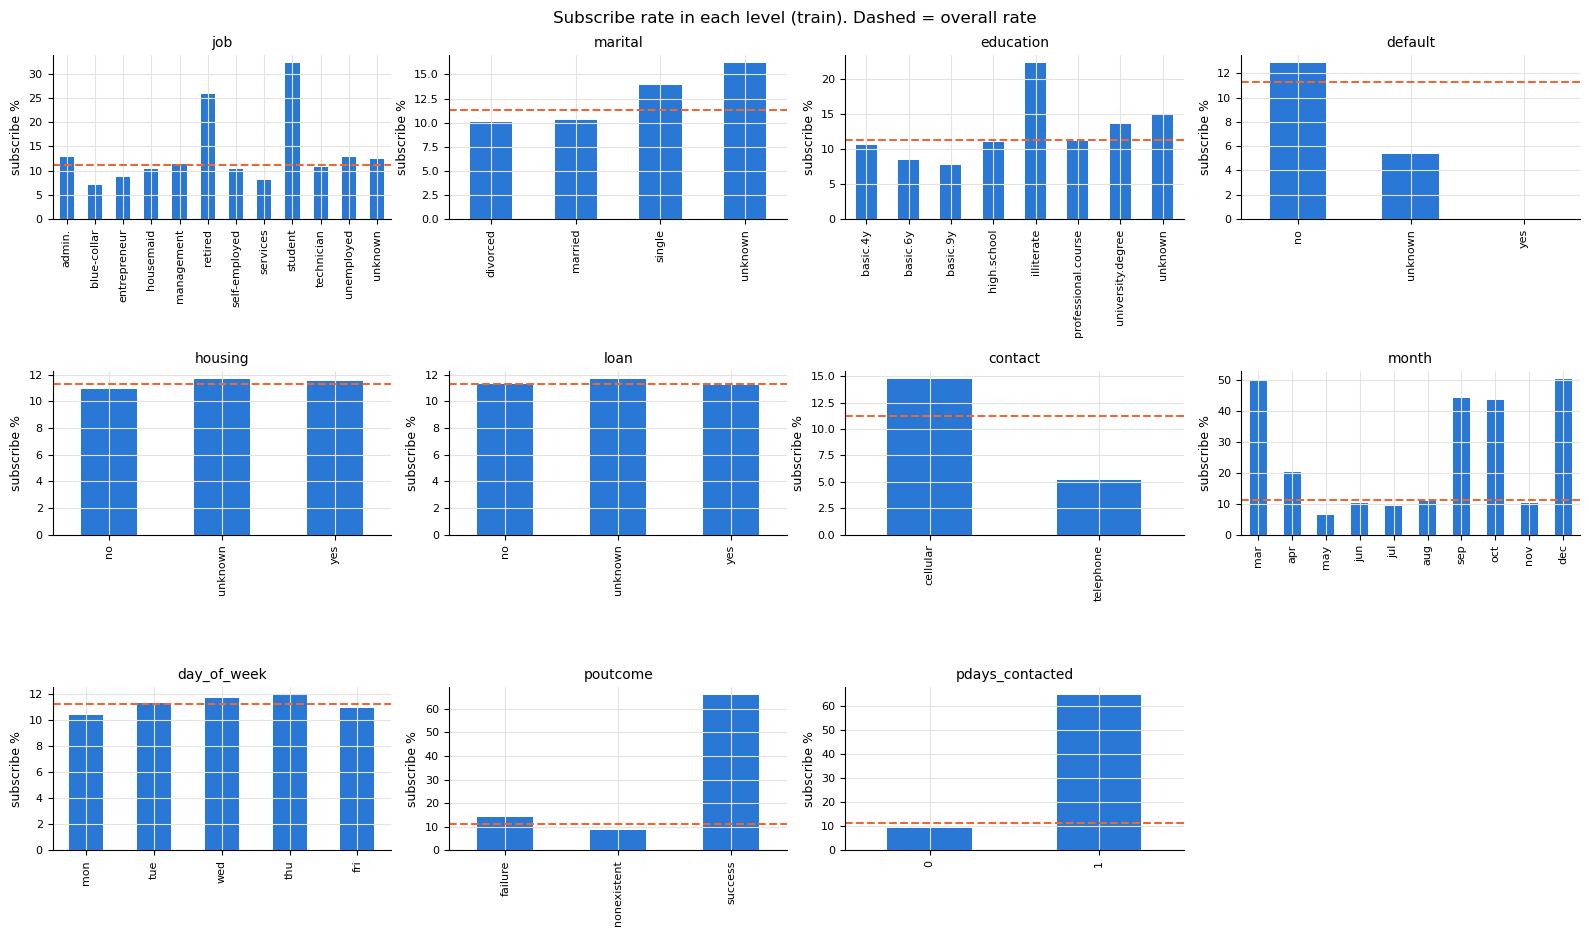

In [38]:
CATF = CAT + ['pdays_contacted']
fig, ax = plt.subplots(3, 4, figsize=(16, 9.5))
for a, c in zip(ax.ravel(), CATF):
    rate = pd.crosstab(tr[c], tr['y'], normalize='index')['yes'] * 100
    if c == 'month': rate = rate.reindex(MONTHS)
    if c == 'day_of_week': rate = rate.reindex(DAYS)
    rate.plot.bar(ax=a, color=BLUE, title=c); a.axhline(tr.y01.mean() * 100, color=ORANGE, ls='--'); a.set_xlabel('')
    a.set_ylabel('subscribe %')
for a in ax.ravel()[len(CATF):]: a.axis('off')
plt.suptitle('Subscribe rate in each level (train). Dashed = overall rate'); plt.tight_layout(); plt.show()

**Reading**
* **Strong:** `poutcome = success` 66 % (vs 9-14 %), `pdays_contacted = 1` 65 % (vs 9 %); `month`: mar / sep / oct / dec 44-50 % vs may 6 %; `contact`: cellular 14.7 % vs telephone 5.2 %.
* **Medium:** `job` (student 32 %, retired 26 %, blue-collar 7 %), `default` (no 12.8 % vs unknown 5.3 %), `education`, `marital` (single 14 %).
* **Nothing:** `housing`, `loan`, `day_of_week`: every bar sits on the line (10.4-12.0 %).

# 10 · Feature selection - categorical features: statistics
| Tool | Tests | Note |
|---|---|---|
| `chi2_contingency` on the level × `y` table (H0: independent) | observed vs expected counts | expected count ≥ 5 in every cell |
| `mutual_info_classif` | any dependency | ranking only |

**Rule:** keep if p < 0.05 **and** MI ≥ 0.001 (so a tiny effect that is significant only because n is large is not kept).

In [39]:
rows = {}
for c in CATF:
    ct = pd.crosstab(tr[c], tr['y'])
    chi2, p, dof, expected = chi2_contingency(ct)          # H0 = feature and y are independent
    rows[c] = {'levels': ct.shape[0], 'chi2': chi2, 'p-value': p, 'min expected count': expected.min()}
cat_tab = pd.DataFrame(rows).T
codes = tr[CATF].apply(lambda s: s.astype('category').cat.codes)
cat_tab['MI'] = mutual_info_classif(codes, tr['y01'], discrete_features=True, random_state=SEED)
cat_tab['p < 0.05'] = cat_tab['p-value'] < 0.05
display(cat_tab.sort_values('MI', ascending=False))
print("default = 'yes' rows in train:", (tr['default'] == 'yes').sum())

,levels,chi2,p-value,min expected count,MI,p < 0.05
pdays_contacted,2,"3,563",0,136,0.03154,True
poutcome,3,"3,472",0,123.2,0.03102,True
month,10,"2,431",0,16.34,0.026,True
contact,2,696,2.265e-153,"1,352",0.01177,True
job,12,804.7,1.894e-165,30.08,0.01017,True
default,3,307.8,1.47e-67,0.2253,0.005437,True
education,8,151.9,1.609e-29,2.028,0.002359,True
marital,4,94.3,2.612e-20,7.661,0.001379,True
day_of_week,5,10.66,0.03066,712.8,0.0001628,True
housing,3,2.695,0.2599,87.76,4.097e-05,False


default = 'yes' rows in train: 2


**Reading**
* `housing` (p = 0.26) and `loan` (p = 0.92): no relation → **reject**.
* `day_of_week`: p = 0.031, just under 0.05, but MI = 0.0002 (rates 10.4-12.0 %) → effect too small → **reject**.
* `default`: `yes` has only 2 rows (min expected 0.23 < 5) and `education = illiterate` has min expected 2.0, so the chi-square assumption fails for those levels → merge them (step 11).
* All others: p ≈ 0, MI 0.0014-0.032.

# 11 · Feature selection summary - categorical features
| Feature | Visual | Chi-square / MI | Decision |
|---|---|---|---|
| `poutcome`, `pdays_contacted` | success / contacted → ~65 % | χ² ≈ 3,500, MI ≈ 0.031 | **keep** (redundancy in step 12) |
| `month` | 6-50 % by month | χ² = 2,431, MI 0.026 | **keep** |
| `contact` | cellular 3× telephone | χ² = 696, MI 0.012 | **keep** |
| `job` | student / retired high | χ² = 805, MI 0.010 | **keep** |
| `default` | unknown low | χ² = 308, MI 0.005 | **keep**, merge `yes` (2 rows) into `unknown` ("not a clear no") |
| `education`, `marital` | small differences | MI 0.0024, 0.0014 | **keep** (weak); merge `illiterate` into `basic.4y` |
| `housing`, `loan`, `day_of_week` | flat | p ≥ 0.03, MI ≤ 0.0002 | **reject** |

In [40]:
tr['default'] = tr['default'].replace({'yes': 'unknown'})            # 2 rows -> merge: "not a clear no"
tr['education'] = tr['education'].replace({'illiterate': 'basic.4y'})  # few rows -> nearest level
for c in ['default', 'education']:
    print(c, '-> min expected count after merging:', round(chi2_contingency(pd.crosstab(tr[c], tr['y']))[3].min(), 1))

CAT_KEEP = ['poutcome', 'pdays_contacted', 'month', 'contact', 'job', 'default', 'education', 'marital']
print('categorical features kept:', CAT_KEEP)
print('rejected: housing, loan, day_of_week')

default -> min expected count after merging: 772.7
education -> min expected count after merging: 156.5
categorical features kept: ['poutcome', 'pdays_contacted', 'month', 'contact', 'job', 'default', 'education', 'marital']
rejected: housing, loan, day_of_week


After merging, every expected count is ≥ 5, so the chi-square results are valid.

# 12 · Redundant-feature analysis
Two features carrying the same information add nothing new and make linear-model weights unstable (multicollinearity).
Tools: correlation matrix of the kept numeric features (flag |r| ≥ 0.8), and crosstabs for categorical pairs that look related.

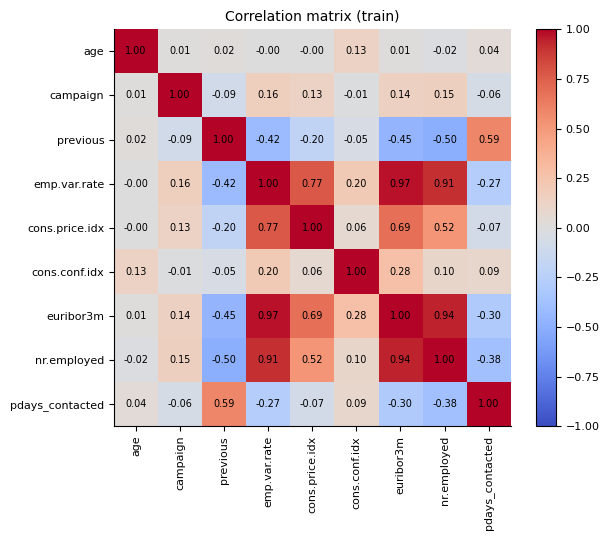

pairs with |r| >= 0.8:


,,r
emp.var.rate,euribor3m,0.9722
euribor3m,nr.employed,0.945
emp.var.rate,nr.employed,0.9065


In [41]:
R = tr[CONT_KEEP + ['pdays_contacted']].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(R, cmap='coolwarm', vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(R))); ax.set_xticklabels(R.columns, rotation=90); ax.set_yticks(range(len(R))); ax.set_yticklabels(R.columns)
for i in range(len(R)):
    for j in range(len(R)): ax.text(j, i, f'{R.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im, fraction=0.045); ax.set_title('Correlation matrix (train)'); plt.tight_layout(); plt.show()

pairs = R.where(np.triu(np.ones(R.shape, dtype=bool), 1)).stack()
print('pairs with |r| >= 0.8:'); display(pairs[pairs.abs() >= 0.8].sort_values(key=abs, ascending=False).to_frame('r'))

In [42]:
print('poutcome vs pdays_contacted:'); display(pd.crosstab(tr['poutcome'], tr['pdays_contacted']))
print('poutcome vs previous:');        display(pd.crosstab(tr['poutcome'], tr['previous']))
print('housing vs loan:');             display(pd.crosstab(tr['housing'], tr['loan']))
fail = tr[tr['poutcome'] == 'failure']
print('poutcome = failure: subscribe % by pdays_contacted ->', (fail.groupby('pdays_contacted')['y01'].mean() * 100).round(1).to_dict())
print('subscribe % by previous ->', (tr.groupby('previous')['y01'].mean() * 100).round(1).to_dict())

poutcome vs pdays_contacted:


pdays_contacted,0,1
poutcome,,
failure,3302,113
nonexistent,28431,0
success,0,1094


poutcome vs previous:


previous,0,1,2,3,4,5,6,7
poutcome,,,,,,,,
failure,0,2967,348,71,27,1,1,0
nonexistent,28431,0,0,0,0,0,0,0
success,0,693,244,104,34,14,4,1


housing vs loan:


loan,no,unknown,yes
housing,,,
no,12820,0,2063
unknown,0,779,0
yes,14337,0,2941


poutcome = failure: subscribe % by pdays_contacted -> {0: 12.7, 1: 51.3}
subscribe % by previous -> {0: 8.8, 1: 21.3, 2: 45.8, 3: 59.4, 4: 52.5, 5: 73.3, 6: 60.0, 7: 0.0}


| Pair | Evidence | Reading | Decision |
|---|---|---|---|
| `emp.var.rate`, `euribor3m`, `nr.employed` | r = 0.97, 0.95, 0.91 | three measures of the same "state of the economy" | **combine with PCA** (step 13) |
| `previous` vs `poutcome` | `previous = 0` ⇔ `poutcome = nonexistent` (28,431 rows) | partly redundant, but `previous` adds the count: rate 21 % at 1 contact, 46-73 % at 2-6 | **keep both** |
| `pdays_contacted` vs `poutcome` | `success` → always 1, `nonexistent` → always 0; they differ only in 113 `failure` rows | in those 113 rows the rate is **51 %** vs 13 % for other failures | **keep both** |
| `housing` vs `loan` | `unknown` is the same 779 rows | already rejected in step 11 | - |

# 13 · Feature extraction
Two tools: **PCA** on the 5 macro columns (slides), and a **domain feature** for age.

### 13.1 PCA on the macro columns
PCA is scale-sensitive, so the columns are standardised first. Rule from the slides: keep the first k PCs that explain ≥ 90 % of the variance.

In [43]:
scaler_m = StandardScaler().fit(tr[MACRO])                  # PCA is scale-sensitive -> standardise first
pca = PCA(random_state=SEED).fit(scaler_m.transform(tr[MACRO]))
pc = pca.transform(scaler_m.transform(tr[MACRO]))
pca_tab = pd.DataFrame(pca.components_, columns=MACRO, index=[f'PC{i+1}' for i in range(len(MACRO))])
pca_tab.insert(0, 'variance %', pca.explained_variance_ratio_ * 100)
pca_tab.insert(1, 'cumulative %', pca.explained_variance_ratio_.cumsum() * 100)
display(pca_tab)

K = int(np.argmax(pca.explained_variance_ratio_.cumsum() >= 0.90) + 1)   # smallest k with >= 90% variance
print('PCs needed for 90% of the variance:', K)

,variance %,cumulative %,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
PC1,69.36,69.36,0.5318,0.4207,0.1319,0.5298,0.4921
PC2,19.66,89.02,-0.04768,-0.1944,0.9737,0.04979,-0.09684
PC3,10.26,99.28,-0.01169,0.8216,0.1204,-0.1816,-0.5266
PC4,0.5032,99.79,0.7942,-0.3171,-0.07245,-0.05336,-0.5105
PC5,0.2138,100,-0.2897,-0.09803,-0.1216,0.8253,-0.4589


PCs needed for 90% of the variance: 3


* **PC1 (69.4 %)**: loads on `emp.var.rate`, `euribor3m`, `nr.employed`, `cons.price.idx` → "overall economy level". **PC2 (19.7 %)** ≈ `cons.conf.idx`. **PC3 (10.3 %)**: `cons.price.idx` against `nr.employed`.
* 2 PCs give 89.0 %, so **k = 3** (99.3 %).

,ANOVA F,corr with y,MI
emp.var.rate,"3,108",-0.2936,0.05644
cons.price.idx,583,-0.1319,0.06864
cons.conf.idx,95.98,0.0539,0.06756
euribor3m,"3,338",-0.3033,0.07228
nr.employed,"4,604",-0.3502,0.06399
PC1,"2,994",-0.2886,0.07277
PC2,417.6,0.1119,0.07558
PC3,"1,330",0.197,0.07323
PC4,0.1736,-0.002296,0.07441
PC5,10.15,0.01755,0.0775


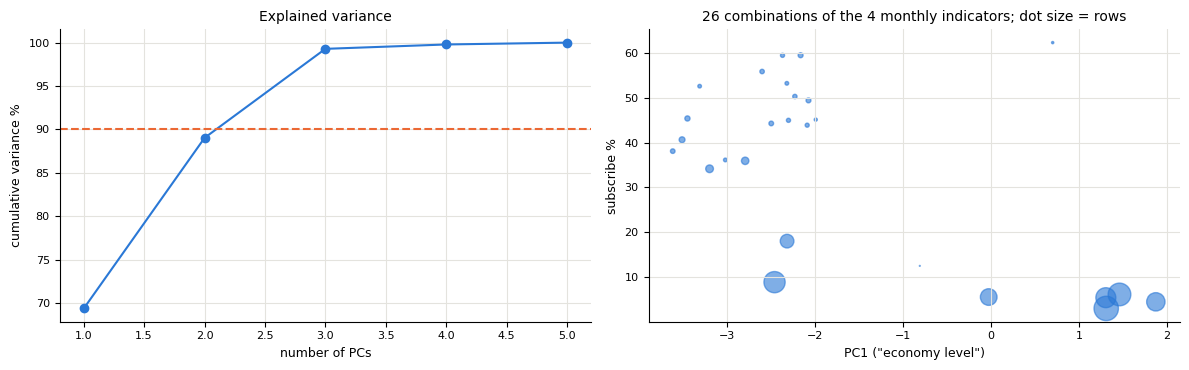

In [44]:
for i in range(len(MACRO)): tr[f'PC{i+1}'] = pc[:, i]
cmp_cols = MACRO + [f'PC{i+1}' for i in range(len(MACRO))]
cmp = pd.DataFrame({'ANOVA F': [f_oneway(*tr.groupby('y')[c].apply(list))[0] for c in cmp_cols],
                    'corr with y': [tr[c].corr(tr['y01']) for c in cmp_cols]}, index=cmp_cols)
cmp['MI'] = mutual_info_classif(tr[cmp_cols], tr['y01'], random_state=SEED)
display(cmp)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(range(1, len(MACRO) + 1), pca.explained_variance_ratio_.cumsum() * 100, marker='o', color=BLUE)
ax[0].axhline(90, color=ORANGE, ls='--'); ax[0].set(xlabel='number of PCs', ylabel='cumulative variance %', title='Explained variance')
per = tr.groupby([c for c in MACRO if c != 'euribor3m']).agg(PC1=('PC1', 'mean'), rate=('y01', 'mean'), rows=('y01', 'size'))   # one dot per month (euribor3m changes daily, so left out)
ax[1].scatter(per['PC1'], per['rate'] * 100, s=per['rows'] / 20, color=BLUE, alpha=0.6)
ax[1].set(xlabel='PC1 ("economy level")', ylabel='subscribe %', title=f'{len(per)} combinations of the 4 monthly indicators; dot size = rows')
plt.tight_layout(); plt.show()

**Reading**
* ANOVA F: PC1 2,994, PC3 1,330, PC2 418; PC4 and PC5 ≈ 0-10, so dropping them loses almost no linear signal.
* MI is ≈ 0.07 for **every** column and PC, even PC4/PC5: the macro values identify the month, and any mix of them still carries "which month". MI cannot separate them here; ANOVA can.
* Right plot: one dot per month. Low PC1 (weak economy, low rates) months have much higher subscribe rates, the same pattern as in step 6.
* **Decision:** replace the 5 macro columns with **PC1-PC3**: 5 → 3 columns, no collinearity (PCs are uncorrelated by construction). Alternative to compare in modelling: keep only `nr.employed`, `cons.price.idx`, `cons.conf.idx`.

### 13.2 Domain feature: age group
`age` relates to `y` as a U-shape (step 6), but a linear model fits only one slope for `age`. Bins from the plots and the life stages: **≤ 25** (students / young), **26-60** (working), **> 60** (retired).

In [45]:
AGE_BINS, AGE_LABELS = [0, 25, 60, 120], ['<=25', '26-60', '>60']
tr['age_group'] = pd.cut(tr['age'], bins=AGE_BINS, labels=AGE_LABELS)
grp = pd.crosstab(tr['age_group'], tr['y'])
display(grp.assign(**{'subscribe %': grp['yes'] / grp.sum(axis=1) * 100}))

chi2, p, _, _ = chi2_contingency(grp)
mi_age = mutual_info_classif(tr[['age']], tr['y01'], random_state=SEED)[0]
mi_grp = mutual_info_classif(tr[['age_group']].apply(lambda s: s.cat.codes), tr['y01'], discrete_features=True, random_state=SEED)[0]
print(f"age (raw):  corr with y = {tr['age'].corr(tr['y01']):.3f}, MI = {mi_age:.4f}")
print(f"age_group:  chi2 = {chi2:.0f}, p = {p:.1e}, MI = {mi_grp:.4f}")

y,no,yes,subscribe %
age_group,,,
<=25,1050,287,21.47
26-60,27772,3089,10.01
>60,407,335,45.15


age (raw):  corr with y = 0.035, MI = 0.0145
age_group:  chi2 = 1040, p = 1.5e-226, MI = 0.0107


* The 3 groups subscribe at **21.5 % / 10.0 % / 45.2 %**: the U-shape is now explicit.
* Raw `age` keeps slightly more MI (0.0145 vs 0.0107) because 3 bins lose detail, but its linear correlation is only 0.035, so a linear model would miss most of it.
* **Decision:** use `age_group` instead of `age` (a tree model in later work can still use raw `age`).

### 13.3 Feature set carried into step 14
| Type | Features |
|---|---|
| numeric (5) | `campaign` (capped at 14), `previous`, `PC1`, `PC2`, `PC3` |
| categorical (9) | `age_group`, `poutcome`, `pdays_contacted`, `month`, `contact`, `job`, `default`, `education`, `marital` |
| rejected | `duration` (leakage), `pdays` (96 % missing), `housing`, `loan`, `day_of_week` (unrelated), 5 macro columns (→ PCs), `age` (→ `age_group`) |

`prepare()` applies every rule learned on train to any DataFrame, so test gets exactly the same treatment. One-hot encoding and scaling come in step 14.

In [46]:
FINAL_NUM = ['campaign', 'previous'] + [f'PC{i+1}' for i in range(K)]
FINAL_CAT = ['age_group', 'poutcome', 'pdays_contacted', 'month', 'contact', 'job', 'default', 'education', 'marital']

def prepare(d):
    # every rule below was learned on train (cap, merges, bins, scaler + PCA); reuse it unchanged on test
    d = d.copy()
    d['campaign'] = d['campaign'].clip(upper=CAMPAIGN_CAP)
    d['pdays_contacted'] = (d['pdays'] != 999).astype(int)
    d['default'] = d['default'].replace({'yes': 'unknown'})
    d['education'] = d['education'].replace({'illiterate': 'basic.4y'})
    d['age_group'] = pd.cut(d['age'], bins=AGE_BINS, labels=AGE_LABELS)
    pcs = pca.transform(scaler_m.transform(d[MACRO]))
    for i in range(K): d[f'PC{i+1}'] = pcs[:, i]
    return d[FINAL_NUM + FINAL_CAT + ['y', 'y01']]

train_fe, test_fe = prepare(train), prepare(test)
print('train_fe', train_fe.shape, '| test_fe', test_fe.shape, '|', len(FINAL_NUM + FINAL_CAT), 'features')
train_fe.head()

train_fe (32940, 16) | test_fe (8236, 16) | 14 features


,campaign,previous,PC1,PC2,PC3,age_group,poutcome,pdays_contacted,month,contact,job,default,education,marital,y,y01
0,1,0,1.308,0.6965,0.3877,26-60,nonexistent,0,may,telephone,housemaid,no,basic.4y,married,no,0
2,1,0,1.308,0.6965,0.3877,26-60,nonexistent,0,may,telephone,services,no,high.school,married,no,0
3,1,0,1.308,0.6965,0.3877,26-60,nonexistent,0,may,telephone,admin.,no,basic.6y,married,no,0
4,1,0,1.308,0.6965,0.3877,26-60,nonexistent,0,may,telephone,services,no,high.school,married,no,0
5,1,0,1.308,0.6965,0.3877,26-60,nonexistent,0,may,telephone,services,unknown,basic.9y,married,no,0
